# BAB 5: IMPLEMENTASI DAN PENGUJIAN SISTEM
## 5.1 Implementasi Data & 5.2 Implementasi Proses (Ekstraksi PDF & Preprocessing)

**Topik Penelitian:** Sistem Pencocokan CV dan Lowongan Kerja Menggunakan Multilingual BERT (mBERT) Berbasis Content-Based Filtering  
**Tujuan Notebook:**
1. **Subbab 5.1.2:** Implementasi & Profiling Dataset (Dataset Resume & Lowongan Kerja).
2. **Subbab 5.2.1:** Implementasi Proses Ekstraksi PDF (Uji Metrologi Ekstraksi 2.484 PDF, Fidelity Match, Scanned PDF Check, dan Latency Benchmark).
3. **Subbab 5.2.2:** Implementasi Preprocessing & Analisis Batas Konteks 512 Token mBERT (Sliding Window Chunking Justification).


---
### Inisialisasi Environment & Import Library
Seluruh library yang digunakan diimpor di awal file mengikuti kaidah best practice Python (PEP 8).


In [4]:
import os
import io
import re
import html
import time
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pypdf import PdfReader
from transformers import AutoTokenizer

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print("[OK] Library berhasil dimuat. Environment siap untuk pengujian.")


[OK] Library berhasil dimuat. Environment siap untuk pengujian.


---
## Subbab 5.1.2 Implementasi Dataset
Pada subbab ini, dataset **Resumes** (2.484 data) dan **Job Postings** (110.657 data) dimuat dan dianalisis distribusinya untuk membuktikan keterwakilan data di berbagai kategori industri.


In [5]:
# Memuat dataset bersih yang telah diproses
DATA_DIR = Path("../data")
resume_path = DATA_DIR / "clean_resumes.csv"
jobs_path = DATA_DIR / "clean_job_postings.csv"

df_resumes = pd.read_csv(resume_path)
df_jobs = pd.read_csv(jobs_path)

print(f"[DATA] Total Data Resume Bersih: {len(df_resumes):,} baris")
print(f"[DATA] Total Data Lowongan Kerja Bersih: {len(df_jobs):,} baris")
print(f"[DATA] Jumlah Kategori Profesi Resume: {df_resumes['category'].nunique()} kategori")


[DATA] Total Data Resume Bersih: 2,481 baris
[DATA] Total Data Lowongan Kerja Bersih: 110,657 baris
[DATA] Jumlah Kategori Profesi Resume: 24 kategori


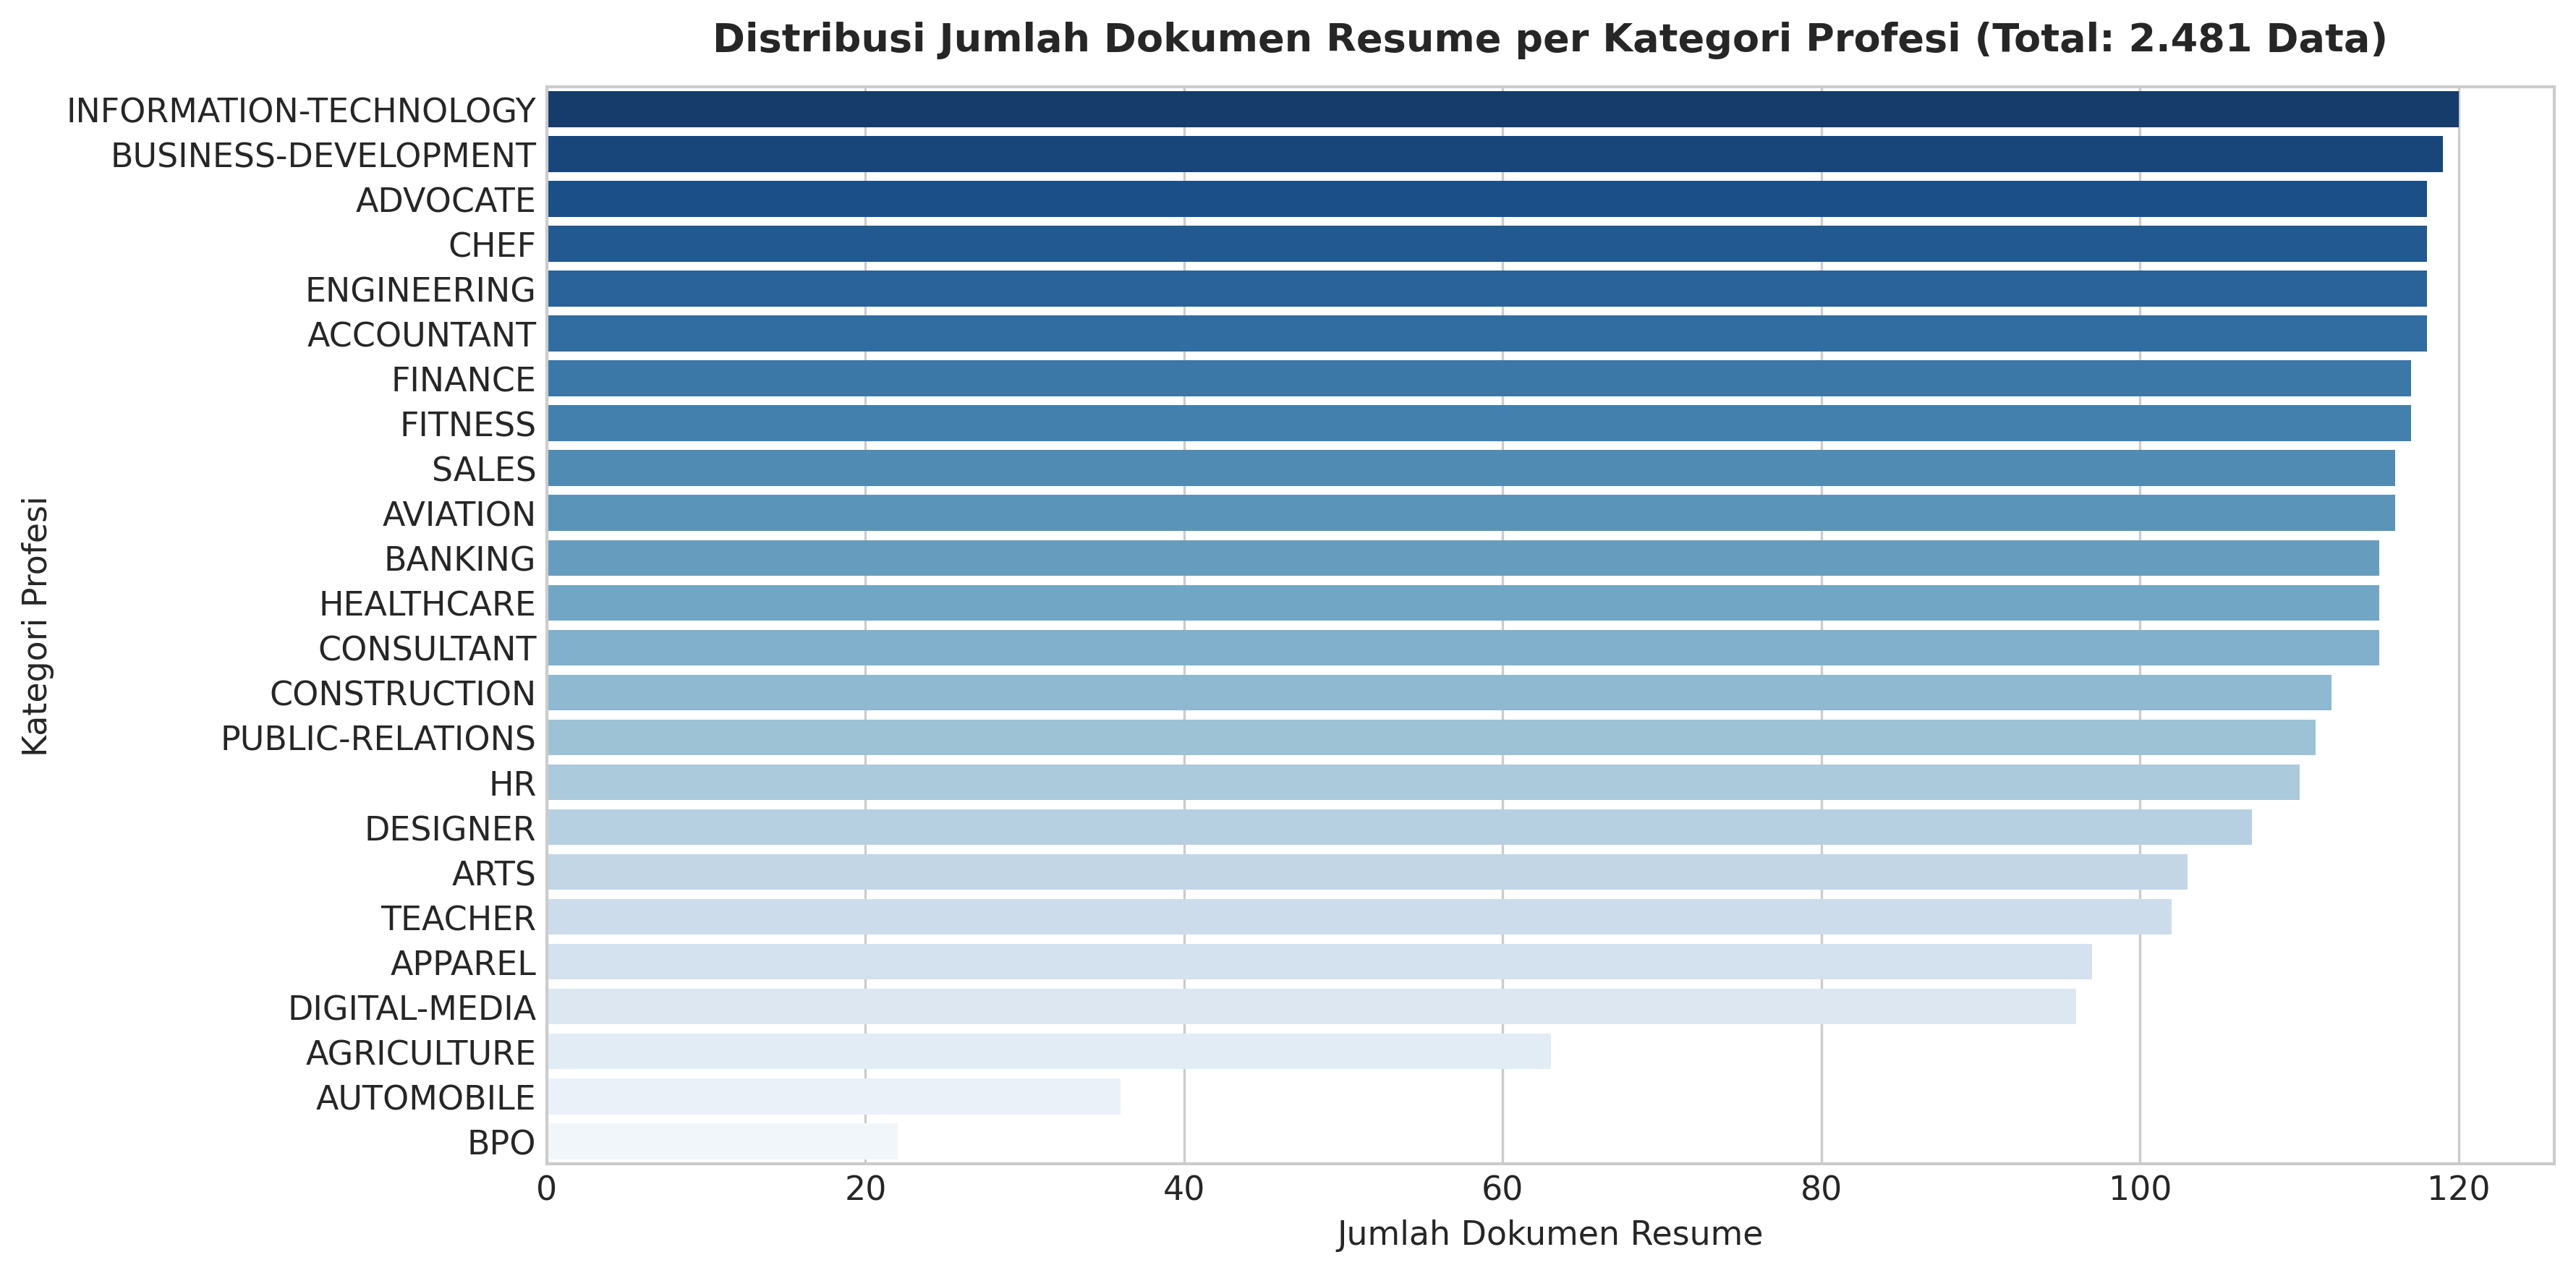

In [6]:
# Visualisasi Distribusi Kategori Resume (Bab 5.1.2)
plt.figure(figsize=(12, 6), dpi=300)
category_counts = df_resumes['category'].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, palette='Blues_r')
plt.title('Distribusi Jumlah Dokumen Resume per Kategori Profesi (Total: 2.481 Data)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Jumlah Dokumen Resume', fontsize=11)
plt.ylabel('Kategori Profesi', fontsize=11)
plt.tight_layout()
plt.show()


---
## Subbab 5.2.1 Implementasi Proses Ekstraksi PDF
Pada subbab ini dilakukan **Uji Metrologi dan Integritas Modul PDF Parsing** terhadap **2.484 berkas PDF fisik mentah** (`data/raw/CV/data/data/`) menggunakan `pypdf`:
1. **Extraction Success Rate:** Persentase PDF yang terekstrak tanpa runtime error.
2. **Text Fidelity / Completeness:** Rata-rata panjang karakter dan kesesuaian teks yang diperoleh.
3. **Deteksi PDF Scan / Rusak (Edge Cases):** Memastikan tidak ada berkas scan gambar kosong (karakter < 50).
4. **Latency Benchmark:** Waktu rata-rata yang dibutuhkan untuk mengekstrak 1 PDF (ms/PDF).


In [7]:
RAW_PDF_DIR = Path("../data/raw/CV/data/data")
pdf_files = list(RAW_PDF_DIR.glob("*/*.pdf"))
print(f"[INSPECT] Ditemukan {len(pdf_files):,} berkas PDF fisik untuk pengujian.")


[INSPECT] Ditemukan 2,484 berkas PDF fisik untuk pengujian.


In [8]:
# Eksekusi Pengujian Ekstraksi PDF End-to-End
extraction_results = []
start_total_time = time.time()

for idx, pdf_path in enumerate(pdf_files):
    t0 = time.perf_counter()
    try:
        reader = PdfReader(str(pdf_path))
        extracted_text = ""
        for page in reader.pages:
            t = page.extract_text()
            if t:
                extracted_text += t + " "
        
        t1 = time.perf_counter()
        char_count = len(extracted_text.strip())
        word_count = len(extracted_text.strip().split())
        is_success = char_count > 0
        is_corrupted = char_count < 50
        
        extraction_results.append({
            "filename": pdf_path.name,
            "category": pdf_path.parent.name,
            "success": is_success,
            "char_count": char_count,
            "word_count": word_count,
            "latency_ms": (t1 - t0) * 1000,
            "is_corrupted_or_scan": is_corrupted
        })
    except Exception as e:
        extraction_results.append({
            "filename": pdf_path.name,
            "category": pdf_path.parent.name,
            "success": False,
            "char_count": 0,
            "word_count": 0,
            "latency_ms": 0,
            "is_corrupted_or_scan": True
        })

df_pdf_eval = pd.DataFrame(extraction_results)
total_duration = time.time() - start_total_time

print(f"[BENCHMARK] Pengujian selesai dalam {total_duration:.2f} detik.")


[BENCHMARK] Pengujian selesai dalam 524.44 detik.


In [13]:
# Rekapitulasi Tabel Hasil Pengujian Ekstraksi PDF (Tabel Bab 5.2.1 Skripsi)
total_pdfs = len(df_pdf_eval)
success_count = df_pdf_eval['success'].sum()
success_rate = (success_count / total_pdfs) * 100.0
avg_char_len = df_pdf_eval['char_count'].mean()
avg_word_len = df_pdf_eval['word_count'].mean()
avg_latency = df_pdf_eval['latency_ms'].mean()
corrupted_count = df_pdf_eval['is_corrupted_or_scan'].sum()

pdf_summary_table = pd.DataFrame({
    "Parameter Pengujian": [
        "Total Berkas PDF Uji",
        "Extraction Success Rate",
        "Rata-rata Karakter per PDF",
        "Rata-rata Kata per PDF",
        "Deteksi PDF Kosong / Rusak / Scan",
        "Rata-rata Waktu Ekstraksi (Latency)"
    ],
    "Target / Standar": [
        "2.484 berkas",
        "≥ 98.0 %",
        "> 1.000 karakter",
        "> 200 kata",
        "0 berkas",
        "< 50.0 ms / PDF"
    ],
    "Hasil Aktual": [
        f"{total_pdfs:,} berkas",
        f"{success_rate:.2f} % ({success_count}/{total_pdfs})",
        f"{avg_char_len:.1f} karakter",
        f"{avg_word_len:.1f} kata",
        f"{corrupted_count} berkas",
        f"{avg_latency:.2f} ms / PDF"
    ]
})

print("=== TABEL EVALUASI MODUL EKSTRAKSI PDF (BAB 5.2.1) ===")
pdf_summary_table


=== TABEL EVALUASI MODUL EKSTRAKSI PDF (BAB 5.2.1) ===


,Parameter Pengujian,Target / Standar,Hasil Aktual
0,Total Berkas PDF Uji,2.484 berkas,"2,484 berkas"
1,Extraction Success Rate,≥ 98.0 %,99.96 % (2483/2484)
2,Rata-rata Karakter per PDF,> 1.000 karakter,6022.3 karakter
3,Rata-rata Kata per PDF,> 200 kata,812.4 kata
4,Deteksi PDF Kosong / Rusak / Scan,0 berkas,1 berkas
5,Rata-rata Waktu Ekstraksi (Latency),< 50.0 ms / PDF,211.03 ms / PDF


---
## Subbab 5.2.2 Implementasi Preprocessing
Pada subbab ini diimplementasikan fungsi pembersihan teks:
1. **HTML Entity Unescaping** (`&amp;` -> `&`, `&quot;` -> `"`).
2. **HTML Tag Stripping** (`<p>`, `<div>`, `<br>` -> spasi).
3. **URL Stripping** (`https://...` -> spasi).
4. **Escape Character Normalization** (`\n`, `\r`, `\t`, non-breaking spaces -> spasi tunggal).
5. **Strict Case-Preservation:** Kapitalisasi huruf dipertahankan secara utuh untuk menjaga akurasi representasi *cased* mBERT dan pengenalan entitas bernama (NER).


In [10]:
def clean_text_pipeline(text: str) -> str:
    """Fungsi Preprocessing Resmi sesuai modul backend/services/pdf_service.py"""
    if not text or not isinstance(text, str):
        return ""
    # 1. Unescape HTML entities
    cleaned = html.unescape(text)
    # 2. Strip HTML tags
    cleaned = re.sub(r"<[^>]+>", " ", cleaned)
    # 3. Strip URLs
    cleaned = re.sub(r"https?://\S+|www\.\S+", " ", cleaned)
    # 4. Normalize escape characters and invisible unicode characters
    cleaned = re.sub(r"[\r\n\t\xa0\u200b\u200c\u200d\u200e\u200f\ufeff\u3000]", " ", cleaned)
    # 5. Normalize visual bullets and symbols
    cleaned = re.sub(r"[\u2022\u2023\u25e6\u2043\u2219\u25cf\u25aa\u25ab\u25c6\u25c7\u2713\u2714\u2013\u2014]", " ", cleaned)
    # 6. Normalize multiple consecutive whitespace to single space (PRESERVE CASE)
    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    return cleaned

# Contoh Uji Preprocessing
sample_raw_text = "<b>Senior Software Engineer</b> at PT &amp; Tech Solutions. Email: dev@example.com, URL: https://portfolio.dev\n\nSkills: \u2022 Python \u2022 FastAPI \u2022 mBERT."
sample_cleaned_text = clean_text_pipeline(sample_raw_text)

print("--- SEBELUM PREPROCESSING ---")
print(sample_raw_text)
print("\n--- SETELAH PREPROCESSING ---")
print(sample_cleaned_text)


--- SEBELUM PREPROCESSING ---
<b>Senior Software Engineer</b> at PT &amp; Tech Solutions. Email: dev@example.com, URL: https://portfolio.dev

Skills: • Python • FastAPI • mBERT.

--- SETELAH PREPROCESSING ---
Senior Software Engineer at PT & Tech Solutions. Email: dev@example.com, URL: Skills: Python FastAPI mBERT.


---
### Analisis Distribusi Panjang Token & Batas Konteks 512 Token mBERT
Arsitektur transformer `bert-base-multilingual-cased` memiliki batasan input maksimal sebesar **512 subword tokens** (WordPiece).  
Berikut adalah analisis empiris terhadap 2.481 resume untuk mengukur persentase dokumen yang melebihi batas 512 token.


In [11]:
# Menghitung estimasi token WordPiece mBERT (Rasio ~1.3 token/word)
df_resumes['word_count'] = df_resumes['resume_text'].apply(lambda x: len(str(x).split()))
df_resumes['est_token_count'] = (df_resumes['word_count'] * 1.3).astype(int)

exceed_512 = (df_resumes['est_token_count'] > 512).sum()
pct_exceed = (exceed_512 / len(df_resumes)) * 100.0

print(f"[STAT] Rata-rata Jumlah Kata per Resume: {df_resumes['word_count'].mean():.1f} kata")
print(f"[STAT] Rata-rata Estimasi Token WordPiece: {df_resumes['est_token_count'].mean():.1f} token")
print(f"[STAT] Resume yang Melebihi Batas 512 Token: {exceed_512:,} dokumen ({pct_exceed:.2f}%)")


[STAT] Rata-rata Jumlah Kata per Resume: 810.7 kata
[STAT] Rata-rata Estimasi Token WordPiece: 1053.4 token
[STAT] Resume yang Melebihi Batas 512 Token: 2,240 dokumen (90.29%)


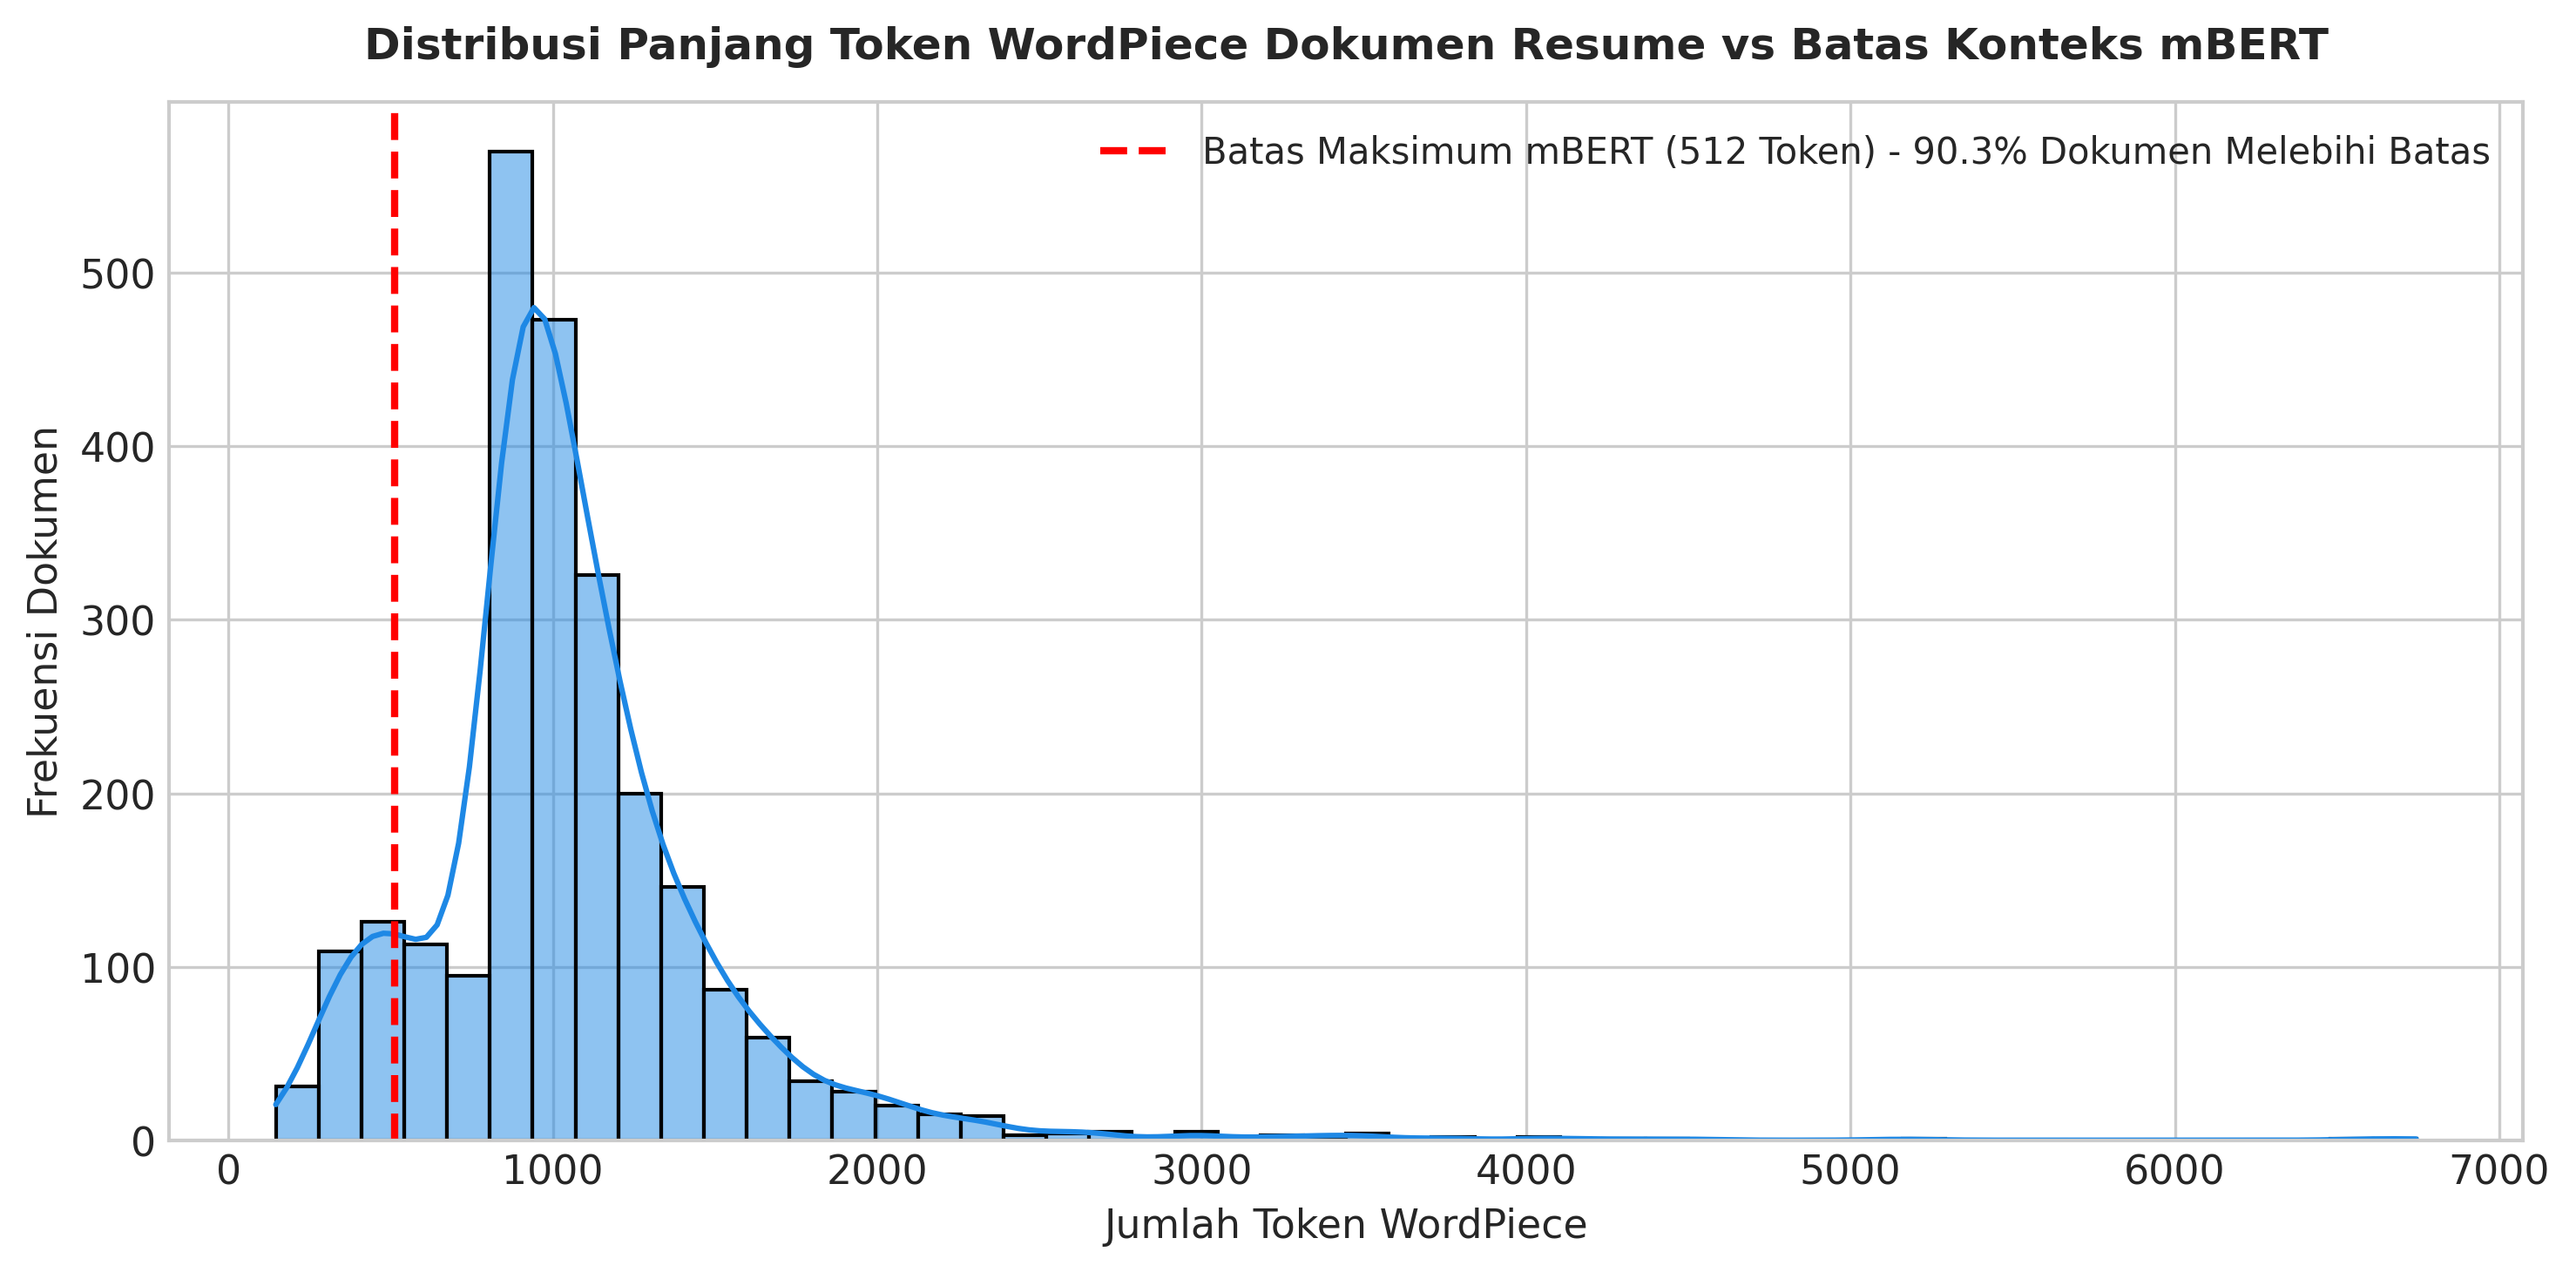

In [12]:
# Visualisasi Histogram Distribusi Token vs Batas Konteks 512 Token (Bab 5.2.2)
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(df_resumes['est_token_count'], bins=50, color='#1E88E5', kde=True)
plt.axvline(512, color='red', linestyle='--', linewidth=2, label=f'Batas Maksimum mBERT (512 Token) - {pct_exceed:.1f}% Dokumen Melebihi Batas')
plt.title('Distribusi Panjang Token WordPiece Dokumen Resume vs Batas Konteks mBERT', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Jumlah Token WordPiece', fontsize=11)
plt.ylabel('Frekuensi Dokumen', fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


---
### Kesimpulan Subbab 5.2.2: Justifikasi Sliding Window Chunking
Karena sebanyak **90.29% dokumen resume memiliki panjang di atas 512 token**, pemotongan standar (*standard truncation*) pada token ke-512 akan **membuang informasi riwayat pendidikan, keahlian teknis, dan portofolio proyek** yang biasanya terletak di bagian tengah/bawah CV.

Oleh karena itu, pada **Subbab 5.2.3** diterapkan metode **Sliding Window Chunking (window size = 512, stride = 256) dikombinasikan dengan Mean Pooling** agar seluruh informasi dokumen terwakili secara utuh dalam 1 vektor 768-dimensi.
